# Week 4 — Four Regression Models
### Modeling Disagreement in LLM Harm Annotation

---

**Goal:** Build 4 regression models with different inputs and outputs.

| Model | X (Input) | y (Output) |
|-------|-----------|------------|
| **Model 1** | Prompt features only | Average harm rating per prompt |
| **Model 2** | Prompt + Annotator features | Average harm rating per prompt |
| **Model 3** | Prompt features only | Individual rating + Predicted average |
| **Model 4** | Annotator features only | Individual rating + Predicted average |

**Important:** Harm_Level is excluded from all models — it is a model-assigned score, not a raw prompt feature.


## 0. Setup

In [7]:
import sys, os, warnings
warnings.filterwarnings('ignore')

def find_repo_root():
    current = os.path.abspath(os.getcwd())
    for _ in range(5):
        if os.path.exists(os.path.join(current, 'data', 'annotations.csv')):
            return current
        current = os.path.dirname(current)
    raise FileNotFoundError("Cannot find repo root.")

REPO_ROOT = find_repo_root()
sys.path.insert(0, os.path.join(REPO_ROOT, 'src'))
os.chdir(REPO_ROOT)
os.makedirs("outputs", exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from data_loader import load_data, get_rating_columns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110

print("All libraries loaded successfully.")

All libraries loaded successfully.


## 1. Load Data

In [8]:
annotations, prompts = load_data()
rating_cols = get_rating_columns(annotations)

print(f"annotations : {annotations.shape}")
print(f"prompts     : {prompts.shape}")

annotations : (100, 314)
prompts     : (150, 65)


## 2. Define Feature Groups



In [ ]:
# ── Prompt features ──────────────────────────
value_cols  = [c for c in prompts.columns if c.startswith('value_topic_')]
action_cols = [c for c in prompts.columns if c.startswith('action_')]
effect_cols = [c for c in prompts.columns if c.startswith('effect_')]
prompt_features = value_cols + action_cols + effect_cols

# ── Annotator features ────────────────────────────────────────
demo_cols   = ['Gender', 'Age', 'Political_Affiliation', 'Education',
               'Social_Media_Frequency', 'Toxicity_Experience', 'Income']
factor_cols = ['Factor_1', 'Factor_2', 'Factor_3']
annotator_features = demo_cols + factor_cols

print(f"Prompt features    : {len(prompt_features)} columns")
print(f"  value_topic_*    : {len(value_cols)}")
print(f"  action_*         : {len(action_cols)}")
print(f"  effect_*         : {len(effect_cols)}")
print()
print(f"Annotator features : {len(annotator_features)} columns")
print(f"  demographic      : {len(demo_cols)}")
print(f"  factor scores    : {len(factor_cols)}")

Prompt features    : 62 columns
  value_topic_*    : 39
  action_*         : 16
  effect_*         : 7

Annotator features : 10 columns
  demographic      : 7
  factor scores    : 3


## 3. Prepare Data

We need two formats:

**Format A — Prompt level (150 rows):** One row per prompt, y = average harm rating.
Used for Model 1 and Model 2.

**Format B — Long format (15,000 rows):** One row per annotator-prompt pair, y = individual rating.
Used for Model 3 and Model 4.


In [10]:
# ── FORMAT A: Prompt-level (150 rows) ────────────────────────
# Compute average harm rating per prompt
avg_ratings = {}
for col in rating_cols:
    q_idx = int(col.replace('Rating_', ''))
    avg_ratings[q_idx] = annotations[col].mean()

prompt_df = prompts[['Question_Index'] + prompt_features].copy()
prompt_df['avg_rating'] = prompt_df['Question_Index'].map(avg_ratings)
prompt_df = prompt_df.dropna(subset=['avg_rating'])

print(f"Format A (prompt-level): {prompt_df.shape}")
print(f"  avg_rating range: {prompt_df['avg_rating'].min():.1f} — {prompt_df['avg_rating'].max():.1f}")

Format A (prompt-level): (150, 64)
  avg_rating range: 5.7 — 89.0


In [11]:
# ── FORMAT B: Long format (15,000 rows) ───────────────────────
rows = []
for _, ann_row in annotations.iterrows():
    for col in rating_cols:
        q_idx  = int(col.replace('Rating_', ''))
        rating = ann_row[col]
        if pd.isna(rating):
            continue
        prompt_row = prompts[prompts['Question_Index'] == q_idx]
        if len(prompt_row) == 0:
            continue

        row = {
            'rating'         : rating,
            'question_index' : q_idx,
            'Participant_ID' : ann_row['Participant_ID'],
        }
        for c in prompt_features:
            row[c] = prompt_row[c].values[0]
        for c in annotator_features:
            row[c] = ann_row[c]
        rows.append(row)

long_df = pd.DataFrame(rows)
long_df_encoded = pd.get_dummies(long_df, columns=demo_cols, drop_first=True)
long_df_encoded = long_df_encoded.fillna(long_df_encoded.median(numeric_only=True))

print(f"Format B (long format): {long_df_encoded.shape}")

Format B (long format): (14725, 96)


## Model 1 — Prompt Features → Average Harm

**Question:** Can we predict the average harm rating of a prompt using only its content features?

- X = value_topic_*, action_*, effect_* (prompt features, no Harm_Level)
- y = average harm rating per prompt
- 150 rows (one per prompt)

OUR CLAIM IS NOT SUCCESFULL WE USED MANY FEATURE IN SMALL DATASET BUT WE CAN IMPROVE IT BY USING CROSS VALIDATION


In [12]:
X1 = prompt_df[prompt_features]
y1 = prompt_df['avg_rating']

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)

model1 = LinearRegression()
model1.fit(X1_train, y1_train)
pred1  = model1.predict(X1_test)
r2_1   = r2_score(y1_test, pred1)
rmse_1 = np.sqrt(mean_squared_error(y1_test, pred1))

print("Model 1 — Prompt features → Average harm:")
print(f"  R²   = {r2_1:.3f}")
print(f"  RMSE = {rmse_1:.2f}")
print()
print(f"Training rows: {X1_train.shape[0]}  |  Test rows: {X1_test.shape[0]}")

Model 1 — Prompt features → Average harm:
  R²   = -0.679
  RMSE = 33.65

Training rows: 120  |  Test rows: 30


## Model 2 — Prompt + Annotator Features → Average Harm

**Question:** Does adding annotator-level features improve average harm prediction?

We aggregate annotator features to prompt level by taking the mean across all annotators per prompt.

- X = prompt features + mean annotator features per prompt
- y = average harm rating per prompt
- 150 rows


In [13]:
# Aggregate annotator features to prompt level
encoded_demo_cols = [c for c in long_df_encoded.columns
                     if any(c.startswith(d + '_') for d in demo_cols)]
agg_cols = factor_cols + encoded_demo_cols

ann_agg = long_df_encoded.groupby('question_index')[agg_cols].mean().reset_index()
ann_agg.columns = ['question_index'] + [f'mean_{c}' for c in agg_cols]

# Merge with prompt features
prompt_df2 = prompt_df.merge(ann_agg, left_on='Question_Index',
                              right_on='question_index', how='left')
prompt_df2 = prompt_df2.dropna()

all_features_2 = prompt_features + [f'mean_{c}' for c in agg_cols]
X2 = prompt_df2[all_features_2]
y2 = prompt_df2['avg_rating']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
pred2  = model2.predict(X2_test)
r2_2   = r2_score(y2_test, pred2)
rmse_2 = np.sqrt(mean_squared_error(y2_test, pred2))

print("Model 2 — Prompt + Annotator features → Average harm:")
print(f"  R²   = {r2_2:.3f}")
print(f"  RMSE = {rmse_2:.2f}")
print()
print(f"Model 1 R² = {r2_1:.3f}  →  Model 2 R² = {r2_2:.3f}")
if r2_2 > r2_1:
    print("  Adding annotator features improves average harm prediction.")
else:
    print("  Adding annotator features does not improve average harm prediction.")

Model 2 — Prompt + Annotator features → Average harm:
  R²   = -3.384
  RMSE = 54.38

Model 1 R² = -0.679  →  Model 2 R² = -3.384
  Adding annotator features does not improve average harm prediction.


## Model 3 — Prompt Features → Individual + Predicted Average

**Question:** Using only prompt features, can we predict individual ratings?
And if we average those individual predictions per prompt, does that match the actual average?

- X = prompt features only
- y = individual rating (15,000 rows)
- Evaluation: both individual R² and predicted-average vs actual-average R²


In [14]:
prompt_feat_cols = [c for c in long_df_encoded.columns
                    if c in prompt_features]

X3 = long_df_encoded[prompt_feat_cols]
y3 = long_df_encoded['rating']

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42
)

model3 = LinearRegression()
model3.fit(X3_train, y3_train)
pred3  = model3.predict(X3_test)

# Individual performance
r2_3_ind   = r2_score(y3_test, pred3)
rmse_3_ind = np.sqrt(mean_squared_error(y3_test, pred3))

print("Model 3 — Prompt features → Individual rating:")
print(f"  R²   = {r2_3_ind:.3f}")
print(f"  RMSE = {rmse_3_ind:.2f}")

Model 3 — Prompt features → Individual rating:
  R²   = 0.273
  RMSE = 32.06


In [15]:
# Predicted average: average the individual predictions per prompt
test_df3 = long_df_encoded.loc[y3_test.index].copy()
test_df3['pred'] = pred3

pred_avg3 = test_df3.groupby('question_index')['pred'].mean()
actual_avg3 = test_df3.groupby('question_index')['rating'].mean()

common3 = pred_avg3.index.intersection(actual_avg3.index)
r2_3_avg   = r2_score(actual_avg3[common3], pred_avg3[common3])
rmse_3_avg = np.sqrt(mean_squared_error(actual_avg3[common3], pred_avg3[common3]))

print("Model 3 — Prompt features → Predicted average:")
print(f"  R²   = {r2_3_avg:.3f}")
print(f"  RMSE = {rmse_3_avg:.2f}")
print()
print("Summary Model 3:")
print(f"  Individual prediction : R²={r2_3_ind:.3f}  RMSE={rmse_3_ind:.2f}")
print(f"  Predicted average     : R²={r2_3_avg:.3f}  RMSE={rmse_3_avg:.2f}")
print()
print("Note: Predicted average R² is typically higher than individual R²")
print("because averaging cancels out individual-level noise.")

Model 3 — Prompt features → Predicted average:
  R²   = 0.626
  RMSE = 15.08

Summary Model 3:
  Individual prediction : R²=0.273  RMSE=32.06
  Predicted average     : R²=0.626  RMSE=15.08

Note: Predicted average R² is typically higher than individual R²
because averaging cancels out individual-level noise.


## Model 4 — Annotator Features → Individual + Predicted Average

**Question:** Using only annotator features (who the person is), can we predict individual ratings?

- X = annotator features only (demographics + Factor_1/2/3)
- y = individual rating (15,000 rows)
- Evaluation: both individual R² and predicted-average vs actual-average R²


In [16]:
ann_feat_cols = factor_cols + [c for c in long_df_encoded.columns
                                if any(c.startswith(d + '_') for d in demo_cols)]

X4 = long_df_encoded[ann_feat_cols]
y4 = long_df_encoded['rating']

X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.2, random_state=42
)

model4 = LinearRegression()
model4.fit(X4_train, y4_train)
pred4  = model4.predict(X4_test)

# Individual performance
r2_4_ind   = r2_score(y4_test, pred4)
rmse_4_ind = np.sqrt(mean_squared_error(y4_test, pred4))

print("Model 4 — Annotator features → Individual rating:")
print(f"  R²   = {r2_4_ind:.3f}")
print(f"  RMSE = {rmse_4_ind:.2f}")

Model 4 — Annotator features → Individual rating:
  R²   = 0.044
  RMSE = 36.77


In [17]:
# Predicted average
test_df4 = long_df_encoded.loc[y4_test.index].copy()
test_df4['pred'] = pred4

pred_avg4   = test_df4.groupby('question_index')['pred'].mean()
actual_avg4 = test_df4.groupby('question_index')['rating'].mean()

common4 = pred_avg4.index.intersection(actual_avg4.index)
r2_4_avg   = r2_score(actual_avg4[common4], pred_avg4[common4])
rmse_4_avg = np.sqrt(mean_squared_error(actual_avg4[common4], pred_avg4[common4]))

print("Model 4 — Annotator features → Predicted average:")
print(f"  R²   = {r2_4_avg:.3f}")
print(f"  RMSE = {rmse_4_avg:.2f}")
print()
print("Summary Model 4:")
print(f"  Individual prediction : R²={r2_4_ind:.3f}  RMSE={rmse_4_ind:.2f}")
print(f"  Predicted average     : R²={r2_4_avg:.3f}  RMSE={rmse_4_avg:.2f}")

Model 4 — Annotator features → Predicted average:
  R²   = -0.006
  RMSE = 24.75

Summary Model 4:
  Individual prediction : R²=0.044  RMSE=36.77
  Predicted average     : R²=-0.006  RMSE=24.75


## 5. Full Model Comparison

Now we compare all 4 models side by side.


                              Model        R²      RMSE
          Model 1: Prompt → Average -0.678604 33.653521
Model 2: Prompt+Annotator → Average -3.383526 54.383633
       Model 3: Prompt → Individual  0.273425 32.059341
    Model 3: Prompt → Pred. Average  0.626295 15.084617
    Model 4: Annotator → Individual  0.044201 36.770324
 Model 4: Annotator → Pred. Average -0.005927 24.748739


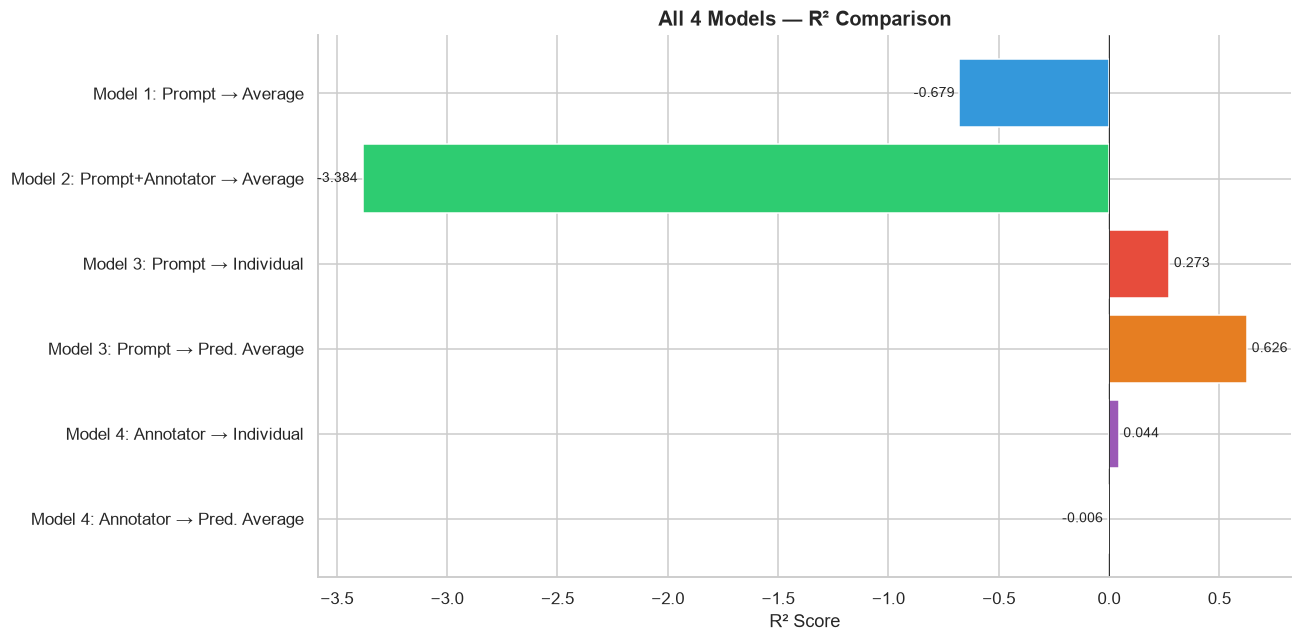

Saved: outputs/fig_4models_comparison.png


In [18]:
results = pd.DataFrame({
    'Model': [
        'Model 1: Prompt → Average',
        'Model 2: Prompt+Annotator → Average',
        'Model 3: Prompt → Individual',
        'Model 3: Prompt → Pred. Average',
        'Model 4: Annotator → Individual',
        'Model 4: Annotator → Pred. Average',
    ],
    'R²': [
        r2_1, r2_2,
        r2_3_ind, r2_3_avg,
        r2_4_ind, r2_4_avg,
    ],
    'RMSE': [
        rmse_1, rmse_2,
        rmse_3_ind, rmse_3_avg,
        rmse_4_ind, rmse_4_avg,
    ]
})

print(results.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#3498db', '#2ecc71', '#e74c3c', '#e67e22', '#9b59b6', '#f39c12']
bars = ax.barh(results['Model'][::-1], results['R²'][::-1],
               color=colors[::-1], edgecolor='white')
ax.bar_label(bars, labels=[f"{v:.3f}" for v in results['R²'][::-1]],
             padding=3, fontsize=9)
ax.set_xlabel('R² Score')
ax.set_title('All 4 Models — R² Comparison', fontweight='bold', fontsize=13)
ax.axvline(0, color='black', linewidth=0.5)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig("outputs/fig_4models_comparison.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_4models_comparison.png")

## 6. Key Insights

### What each comparison tells us

**Model 1 vs Model 2:**
> Does adding annotator information improve average harm prediction?
> If Model 2 R² > Model 1 R² → annotator profiles matter even for average prediction.

**Model 3 vs Model 4:**
> Which is more predictive for individual ratings — knowing the prompt or knowing the annotator?
> This directly addresses our research question about the sources of disagreement.

**Individual vs Predicted Average (Models 3 and 4):**
> Predicted average R² is typically higher than individual R².
> This is because averaging across annotators cancels out individual-level noise,
> leaving only the systematic variance that the model can capture.

### Next steps
- [ ] Mixed-effects model — annotator as random effect
- [ ] Add interaction terms (Factor × prompt type)
- [ ] ELFEN linguistic features


In [19]:
print("Final summary:")
print(f"  Model 1 (Prompt → Average)           : R²={r2_1:.3f}")
print(f"  Model 2 (Prompt+Annotator → Average) : R²={r2_2:.3f}")
print(f"  Model 3 (Prompt → Individual)        : R²={r2_3_ind:.3f}")
print(f"  Model 3 (Prompt → Pred. Average)     : R²={r2_3_avg:.3f}")
print(f"  Model 4 (Annotator → Individual)     : R²={r2_4_ind:.3f}")
print(f"  Model 4 (Annotator → Pred. Average)  : R²={r2_4_avg:.3f}")

Final summary:
  Model 1 (Prompt → Average)           : R²=-0.679
  Model 2 (Prompt+Annotator → Average) : R²=-3.384
  Model 3 (Prompt → Individual)        : R²=0.273
  Model 3 (Prompt → Pred. Average)     : R²=0.626
  Model 4 (Annotator → Individual)     : R²=0.044
  Model 4 (Annotator → Pred. Average)  : R²=-0.006
